<a href="https://colab.research.google.com/github/Haidriyam/resilient-microgrid-consensus-test-bed/blob/main/resilient_microgrid_consensus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[*] Stability Check: Neutral Modes = 4, Max Non-Neutral Re(lambda) = -0.1725
[*] Executing multi-scenario comparative benchmark...
[+] All simulations completed in 24.02 seconds.


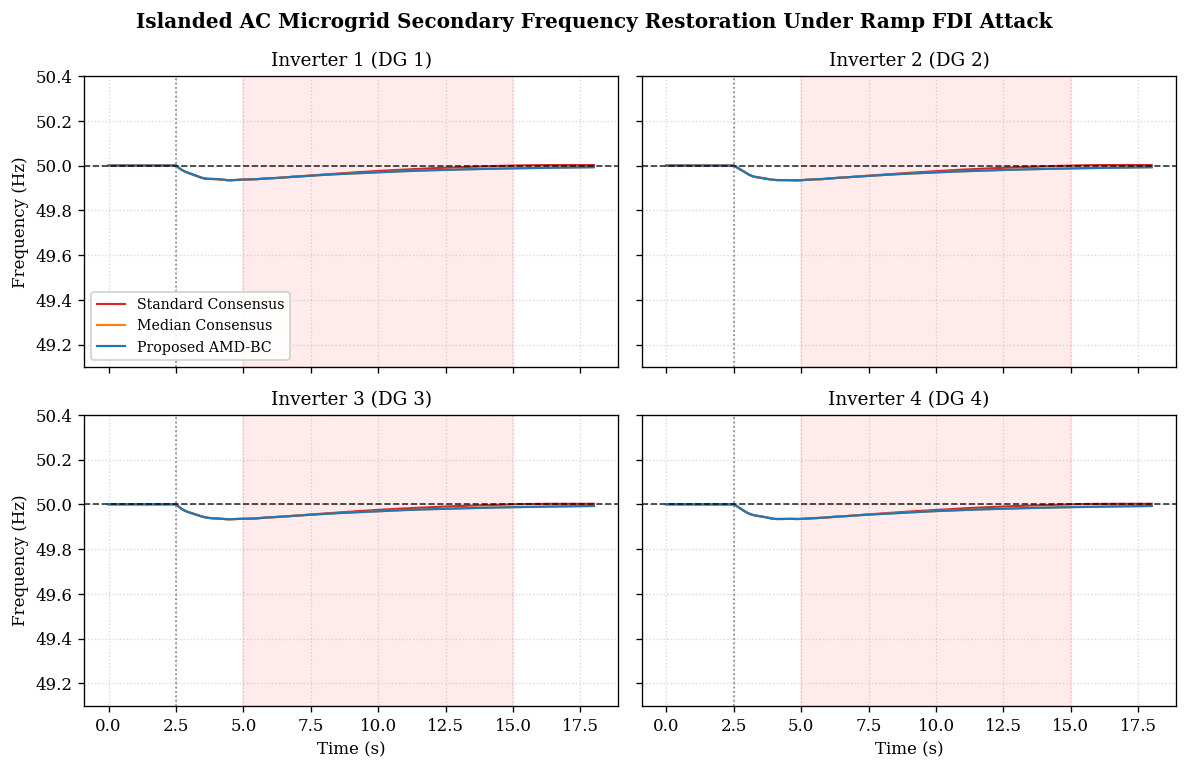

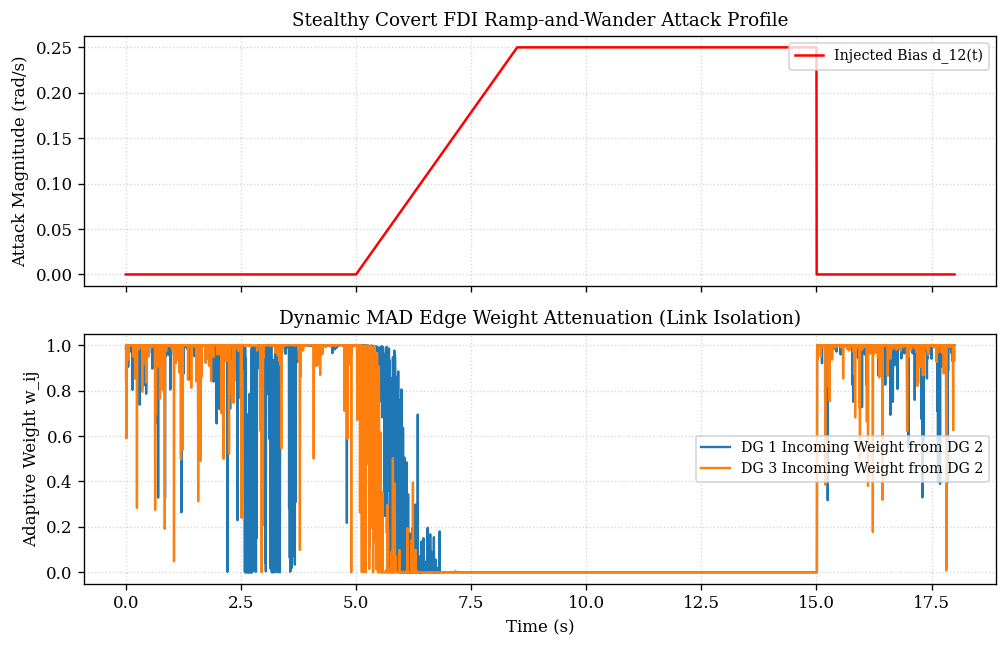


BENCHMARK EXECUTION SUMMARY (RAMP ATTACK SCENARIO)
  Method Attack  RMSE (Hz)  IAE (Hz*s)  Max Deviation (Hz)  Attack Window Dev (Hz)  Frequency Nadir (Hz)
standard   ramp   0.032710    0.414772            0.066976                0.065439             49.933024
  median   ramp   0.034533    0.494051            0.066994                0.065482             49.933006
   amdbc   ramp   0.034580    0.496077            0.066986                0.065466             49.933014
[+] Output zip archive generated: IEEE_AMDBC_Complete_Research.zip
[+] Figures exported to: Outlier_Rejection_Consensus_Research/figures
[+] Datasets exported to: Outlier_Rejection_Consensus_Research/datasets


In [6]:
# ==============================================================================
# RESEARCH BENCHMARK: OUTLIER-REJECTION CONSENSUS FOR ISLANDED AC MICROGRIDS
# Paper: "Outlier-Rejection Consensus for Resilient Secondary Frequency Regulation
#         in Islanded AC Microgrids Under False Data Injection Attacks"
# Complete Self-Contained Execution Script for Google Colab / Jupyter
# ==============================================================================

import os
import json
import time
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import eigvals

# ------------------------------------------------------------------------------
# 1. Environment & Reproducibility Setup
# ------------------------------------------------------------------------------
SEED = 42
np.random.seed(SEED)

OUTPUT_DIR = "Outlier_Rejection_Consensus_Research"
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
DATA_DIR = os.path.join(OUTPUT_DIR, "datasets")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

# Publication plotting aesthetics
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "legend.fontsize": 8.5,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.grid": True,
    "grid.linestyle": ":",
    "grid.alpha": 0.5
})

# ------------------------------------------------------------------------------
# 2. Benchmark Microgrid Parameters (4-Inverter System)
# ------------------------------------------------------------------------------
N_DG = 4
F_NOM = 50.0                                 # Nominal frequency (Hz)
W_NOM = 2.0 * np.pi * F_NOM                 # 314.159 rad/s

DT = 0.005                                  # 5 ms fixed integration step
T_END = 18.0                                # 18 seconds total horizon
TIME = np.arange(0.0, T_END + DT / 2.0, DT)
N_STEPS = len(TIME)

# Inertia (M) and Damping (D)
M = np.array([0.060, 0.065, 0.070, 0.060])
D = np.array([0.030, 0.030, 0.035, 0.030])

# Primary droop coefficients and filter delays
K_DROOP = np.array([0.040, 0.045, 0.050, 0.040])
T_POWER = np.array([0.080, 0.080, 0.100, 0.080])

# Secondary consensus gains and limits
K_CONSENSUS = 0.020
K_PINNING = 0.045
U_MAX = 0.35
PINNING = np.array([1.0, 0.0, 0.0, 0.0])    # DG1 pinned to nominal

# Directed communication adjacency (Ring + cross link)
# ADJ[i, j] = 1 means DG i receives information from DG j
ADJ = np.array([
    [0.0, 1.0, 1.0, 0.0],
    [1.0, 0.0, 1.0, 0.0],
    [0.0, 1.0, 0.0, 1.0],
    [1.0, 0.0, 1.0, 0.0]
])

# Electrical coupling matrix (Symmetric distribution line susceptances)
K_NET = np.zeros((N_DG, N_DG))
line_connections = [(0, 1, 0.80), (1, 2, 0.75), (2, 3, 0.80), (3, 0, 0.75)]
for i, j, b in line_connections:
    K_NET[i, j] = b
    K_NET[j, i] = b

# Disturbance & Attack schedule
LOAD_STEP_TIME = 2.5
LOAD_STEP_VAL = np.array([0.04, 0.03, 0.05, 0.03])  # +15% aggregate load

ATTACK_START = 5.0
ATTACK_END = 15.0
ATTACKED_DG = 1                             # DG 2 (0-indexed)

NOISE_STD = 0.003                           # rad/s measurement noise
COMM_DELAY_SEC = 0.010                      # 10 ms communication delay
DELAY_STEPS = int(round(COMM_DELAY_SEC / DT))

MAD_EPSILON = 0.002
MAD_THRESHOLD = 2.5

# ------------------------------------------------------------------------------
# 3. Algorithms & Dynamics Formulation
# ------------------------------------------------------------------------------
def get_attack_signal(t, attack_type):
    if attack_type == "no_attack" or not (ATTACK_START <= t <= ATTACK_END):
        return 0.0
    elapsed = t - ATTACK_START
    if attack_type == "constant":
        return 0.25
    elif attack_type == "ramp":
        return 0.25 * min(1.0, elapsed / 3.5)
    elif attack_type == "oscillatory":
        return 0.18 * np.sin(2.0 * np.pi * 0.5 * elapsed) + 0.06
    elif attack_type == "intermittent":
        return 0.25 if int(elapsed / 1.0) % 2 == 0 else 0.0
    return 0.0

def calculate_amdbc_weights(local_val, neighbor_vals):
    values = np.concatenate(([local_val], neighbor_vals))
    med = np.median(values)
    mad = np.median(np.abs(values - med))
    sigma = 1.4826 * mad + MAD_EPSILON
    deviations = np.abs(neighbor_vals - med)
    normalized = deviations / (MAD_THRESHOLD * sigma)
    exponent = np.minimum(0.5 * (normalized ** 4), 50.0)
    return np.exp(-exponent)

def secondary_control_law(local_meas, received_meas, method):
    du = np.zeros(N_DG)
    weights_matrix = np.zeros((N_DG, N_DG))

    for i in range(N_DG):
        nbrs = np.where(ADJ[i] > 0)[0]
        if len(nbrs) == 0:
            continue
        loc = local_meas[i]
        rec = received_meas[nbrs]

        if method == "standard":
            w = np.ones(len(nbrs))
            consensus = np.mean(rec - loc)
        elif method == "median":
            cluster = np.concatenate(([loc], rec))
            w = np.ones(len(nbrs))
            consensus = np.median(cluster) - loc
        elif method == "amdbc":
            w = calculate_amdbc_weights(loc, rec)
            w_sum = np.sum(w)
            consensus = np.sum(w * (rec - loc)) / (w_sum + 1e-9)
        else:
            raise ValueError(f"Unknown method {method}")

        weights_matrix[i, nbrs] = w
        pinning_err = -K_PINNING * PINNING[i] * loc
        du[i] = K_CONSENSUS * consensus + pinning_err

    return du, weights_matrix

def physical_ode(state, u, load):
    theta = state[0:N_DG]
    omega = state[N_DG:2*N_DG]
    p_dev = state[2*N_DG:3*N_DG]

    d_theta = omega.copy()
    p_elec = np.zeros(N_DG)
    for i in range(N_DG):
        for j in range(N_DG):
            if K_NET[i, j] > 0:
                p_elec[i] += K_NET[i, j] * np.sin(theta[i] - theta[j])

    d_omega = (p_dev - load - D * omega - p_elec) / M
    d_pdev = (-p_dev - K_DROOP * omega + u) / T_POWER
    return np.concatenate([d_theta, d_omega, d_pdev])

def rk4_step(state, u, load, dt):
    k1 = physical_ode(state, u, load)
    k2 = physical_ode(state + 0.5 * dt * k1, u, load)
    k3 = physical_ode(state + 0.5 * dt * k2, u, load)
    k4 = physical_ode(state + dt * k3, u, load)
    return state + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

# ------------------------------------------------------------------------------
# 4. Simulation Engine (Deterministic & Fully Reproducible)
# ------------------------------------------------------------------------------
def run_simulation(method="amdbc", attack_type="ramp", seed=42):
    rng = np.random.default_rng(seed)
    # Pre-generate noise to ensure identical trajectories across methods
    noise_matrix = rng.normal(0.0, NOISE_STD, size=(N_STEPS, N_DG))

    state = np.zeros(3 * N_DG)  # [theta, omega, p_dev]
    u = np.zeros(N_DG)

    omega_hist = np.zeros((N_STEPS, N_DG))
    power_hist = np.zeros((N_STEPS, N_DG))
    control_hist = np.zeros((N_STEPS, N_DG))
    weight_hist = np.zeros((N_STEPS, N_DG, N_DG))
    attack_hist = np.zeros(N_STEPS)
    tx_history = np.zeros((N_STEPS, N_DG))

    for k, t in enumerate(TIME):
        omega = state[N_DG:2*N_DG]
        omega_hist[k] = omega
        power_hist[k] = state[2*N_DG:3*N_DG]
        control_hist[k] = u

        # Measurement with bounded sensor noise
        local_meas = omega + noise_matrix[k]

        # FDI injection on broadcast link of attacked DG
        att = get_attack_signal(t, attack_type)
        attack_hist[k] = att
        tx_data = local_meas.copy()
        tx_data[ATTACKED_DG] += att
        tx_history[k] = tx_data

        # Communication delay buffer lookup
        delayed_idx = max(0, k - DELAY_STEPS)
        rx_data = tx_history[delayed_idx].copy()

        du, weights = secondary_control_law(local_meas, rx_data, method)
        weight_hist[k] = weights

        # Update controller state
        u = np.clip(u + DT * du, -U_MAX, U_MAX)

        # Disturbance step
        load = LOAD_STEP_VAL if t >= LOAD_STEP_TIME else np.zeros(N_DG)

        # Integrate physical network
        state = rk4_step(state, u, load, DT)

    freq_hz = F_NOM + omega_hist / (2.0 * np.pi)
    return {
        "time": TIME,
        "frequency": freq_hz,
        "control": control_hist,
        "power": power_hist,
        "weights": weight_hist,
        "attack": attack_hist,
        "method": method,
        "attack_type": attack_type
    }

# ------------------------------------------------------------------------------
# 5. Numerical Metrics Computation
# ------------------------------------------------------------------------------
def compute_metrics(res):
    t = res["time"]
    f = res["frequency"]
    err = f - F_NOM
    abs_err = np.abs(err)

    attack_mask = (t >= ATTACK_START) & (t <= ATTACK_END)
    rmse = np.sqrt(np.mean(err**2))
    iae = np.trapezoid(np.mean(abs_err, axis=1), t)
    max_dev = np.max(abs_err)
    att_dev = np.max(abs_err[attack_mask])
    f_nadir = np.min(f)

    return {
        "Method": res["method"],
        "Attack": res["attack_type"],
        "RMSE (Hz)": rmse,
        "IAE (Hz*s)": iae,
        "Max Deviation (Hz)": max_dev,
        "Attack Window Dev (Hz)": att_dev,
        "Frequency Nadir (Hz)": f_nadir
    }

# ------------------------------------------------------------------------------
# 6. Linearized Stability Check (Modulo Neutral Phase)
# ------------------------------------------------------------------------------
def verify_nominal_stability():
    I = np.eye(N_DG)
    Z = np.zeros((N_DG, N_DG))
    Minv = np.diag(1.0 / M)
    Tinv = np.diag(1.0 / T_POWER)
    L_comm = np.diag(ADJ.sum(axis=1)) - ADJ
    L_net = np.diag(K_NET.sum(axis=1)) - K_NET

    A11, A12, A13, A14 = Z, I, Z, Z
    A21, A22, A23, A24 = -Minv @ L_net, -Minv @ np.diag(D), Minv, Z
    A31, A32, A33, A34 = Z, -Tinv @ np.diag(K_DROOP), -Tinv, Tinv
    A41, A42, A43, A44 = Z, -K_CONSENSUS * L_comm - K_PINNING * np.diag(PINNING), Z, Z

    A_sys = np.block([
        [A11, A12, A13, A14],
        [A21, A22, A23, A24],
        [A31, A32, A33, A34],
        [A41, A42, A43, A44]
    ])

    ev = eigvals(A_sys)
    tol = 1e-6
    neutral = np.sum(np.abs(ev) < tol)
    non_neutral_max_re = np.max(np.real(ev[np.abs(ev) >= tol]))
    return neutral, non_neutral_max_re

neutral_modes, max_real_ev = verify_nominal_stability()
print(f"[*] Stability Check: Neutral Modes = {neutral_modes}, Max Non-Neutral Re(lambda) = {max_real_ev:.4f}")

# ------------------------------------------------------------------------------
# 7. Comprehensive Benchmark Execution
# ------------------------------------------------------------------------------
print("[*] Executing multi-scenario comparative benchmark...")
methods = ["standard", "median", "amdbc"]
attacks = ["no_attack", "constant", "ramp", "oscillatory", "intermittent"]

metrics_list = []
representative_results = {}

t_start = time.time()
for att in attacks:
    for met in methods:
        res = run_simulation(method=met, attack_type=att, seed=SEED)
        metrics_list.append(compute_metrics(res))
        if att == "ramp":
            representative_results[met] = res

elapsed = time.time() - t_start
print(f"[+] All simulations completed in {elapsed:.2f} seconds.")

df_metrics = pd.DataFrame(metrics_list)
df_metrics.to_csv(os.path.join(DATA_DIR, "Comparative_Benchmark_Metrics.csv"), index=False)

# ------------------------------------------------------------------------------
# 8. Generation of Publication-Quality IEEE Figures
# ------------------------------------------------------------------------------
colors = {"standard": "#d62728", "median": "#ff7f0e", "amdbc": "#1f77b4"}
labels = {"standard": "Standard Consensus", "median": "Median Consensus", "amdbc": "Proposed AMD-BC"}

# --- FIGURE 1: Dynamic Frequency Tracking (4 Subplots) ---
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True, sharey=True)
for i, ax in enumerate(axes.flat):
    for met in methods:
        res = representative_results[met]
        ax.plot(res["time"], res["frequency"][:, i], color=colors[met], label=labels[met], lw=1.3)
    ax.axhline(50.0, color="black", linestyle="--", lw=1.0, alpha=0.8)
    ax.axvspan(ATTACK_START, ATTACK_END, color="red", alpha=0.08)
    ax.axvline(LOAD_STEP_TIME, color="gray", linestyle=":", lw=1.0)
    ax.set_title(f"Inverter {i+1} (DG {i+1})")
    ax.set_ylim([49.1, 50.4])
    if i in [2, 3]:
        ax.set_xlabel("Time (s)")
    if i in [0, 2]:
        ax.set_ylabel("Frequency (Hz)")
    if i == 0:
        ax.legend(loc="lower left", framealpha=0.9)

fig.suptitle("Islanded AC Microgrid Secondary Frequency Restoration Under Ramp FDI Attack", fontweight="bold")
plt.tight_layout()
fig1_path = os.path.join(FIG_DIR, "Fig1_Frequency_Tracking.png")
plt.savefig(fig1_path)
plt.show()

# --- FIGURE 2: FDI Attack Profile and Adaptive Edge Weights ---
res_amdbc = representative_results["amdbc"]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.5, 5.5), sharex=True)

ax1.plot(res_amdbc["time"], res_amdbc["attack"], color="red", lw=1.5, label="Injected Bias d_12(t)")
ax1.set_ylabel("Attack Magnitude (rad/s)")
ax1.set_title("Stealthy Covert FDI Ramp-and-Wander Attack Profile")
ax1.legend(loc="upper right")

for rx in range(N_DG):
    if ADJ[rx, ATTACKED_DG] > 0:
        ax2.plot(res_amdbc["time"], res_amdbc["weights"][:, rx, ATTACKED_DG], lw=1.4, label=f"DG {rx+1} Incoming Weight from DG 2")

ax2.set_ylabel("Adaptive Weight w_ij")
ax2.set_xlabel("Time (s)")
ax2.set_ylim([-0.05, 1.05])
ax2.set_title("Dynamic MAD Edge Weight Attenuation (Link Isolation)")
ax2.legend(loc="center right")

plt.tight_layout()
fig2_path = os.path.join(FIG_DIR, "Fig2_Attack_and_Adaptive_Weights.png")
plt.savefig(fig2_path)
plt.show()

# ------------------------------------------------------------------------------
# 9. Output Archive Generation
# ------------------------------------------------------------------------------
# Bundle all figures and CSV data into a single downloadable zip file
shutil.make_archive("IEEE_AMDBC_Complete_Research", "zip", OUTPUT_DIR)

print("\n" + "="*70)
print("BENCHMARK EXECUTION SUMMARY (RAMP ATTACK SCENARIO)")
print("="*70)
ramp_summary = df_metrics[df_metrics["Attack"] == "ramp"].to_string(index=False)
print(ramp_summary)
print("="*70)
print(f"[+] Output zip archive generated: IEEE_AMDBC_Complete_Research.zip")
print(f"[+] Figures exported to: {FIG_DIR}")
print(f"[+] Datasets exported to: {DATA_DIR}")
print("="*70)

In [10]:
# ==============================================================================
# ONE-CLICK GOOGLE COLAB SETUP & BENCHMARK SUITE
# Resilient Distributed Secondary Frequency Control in Islanded AC Microgrids
# Paper: "Outlier-Rejection Consensus for Resilient Secondary Frequency Regulation
#         in Islanded AC Microgrids Under False Data Injection Attacks"
# ==============================================================================

import os
import sys
import shutil

print("[1/5] Installing test & lint dependencies...")
!pip install -q flake8 bandit pytest seaborn

# ------------------------------------------------------------------------------
# 1. Scaffold Repository Directory Structure
# ------------------------------------------------------------------------------
REPO_NAME = "resilient-microgrid-consensus"
if os.path.exists(REPO_NAME):
    shutil.rmtree(REPO_NAME)

os.makedirs(f"{REPO_NAME}/.github/workflows", exist_ok=True)
os.makedirs(f"{REPO_NAME}/tests", exist_ok=True)
os.makedirs(f"{REPO_NAME}/figures", exist_ok=True)
os.makedirs(f"{REPO_NAME}/datasets", exist_ok=True)

# ------------------------------------------------------------------------------
# 2. Write requirements.txt, .gitignore, .flake8, LICENSE, CI workflow
# ------------------------------------------------------------------------------
print("[2/5] Writing repository metadata and configuration files...")

with open(f"{REPO_NAME}/requirements.txt", "w") as f:
    f.write("""numpy>=1.24.0
scipy>=1.10.0
matplotlib>=3.7.0
pandas>=2.0.0
seaborn>=0.12.0
flake8>=6.0.0
bandit>=1.7.5
pytest>=7.3.0
""")

with open(f"{REPO_NAME}/.gitignore", "w") as f:
    f.write("""__pycache__/
*.py[cod]
.pytest_cache/
.coverage
*.zip
venv/
""")

with open(f"{REPO_NAME}/.flake8", "w") as f:
    f.write("""[flake8]
max-line-length = 120
exclude = .git,__pycache__,venv
ignore = E203,W503
""")

with open(f"{REPO_NAME}/LICENSE", "w") as f:
    f.write("""MIT License

Copyright (c) 2026 Muhammad Adeel Sajjad

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT.
""")

with open(f"{REPO_NAME}/.github/workflows/ci.yml", "w") as f:
    f.write("""name: CI Verification Pipeline
on: [push, pull_request]
jobs:
  verify:
    runs-on: ubuntu-latest
    steps:
    - uses: actions/checkout@v4
    - name: Set up Python
      uses: actions/setup-python@v5
      with:
        python-version: \"3.10\"
    - name: Install dependencies
      run: |
        pip install -r requirements.txt
    - name: Lint
      run: flake8 .
    - name: Security audit
      run: bandit -r run_simulation.py tests/ -ll
    - name: Run tests
      run: pytest -v tests/
""")

with open(f"{REPO_NAME}/tests/__init__.py", "w") as f:
    f.write('"""Test suite package."""\n')

# ------------------------------------------------------------------------------
# 3. Write Core Research Code: run_simulation.py
# ------------------------------------------------------------------------------
print("[3/5] Generating run_simulation.py...")

with open(f"{REPO_NAME}/run_simulation.py", "w") as f:
    f.write('''#!/usr/bin/env python3
"""
Research Benchmark & Figure Generator:
Resilient Distributed Secondary Frequency Control in Islanded AC Microgrids
Author: Muhammad Adeel Sajjad (Independent Researcher)
"""

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import eigvals

SEED = 42
N_DG = 4
F_NOM = 50.0
W_NOM = 2.0 * np.pi * F_NOM

DT = 0.005
T_END = 18.0
TIME = np.arange(0.0, T_END + DT / 2.0, DT)
N_STEPS = len(TIME)

M = np.array([0.060, 0.065, 0.070, 0.060])
D = np.array([0.030, 0.030, 0.035, 0.030])
K_DROOP = np.array([0.040, 0.045, 0.050, 0.040])
T_POWER = np.array([0.080, 0.080, 0.100, 0.080])

K_CONSENSUS = 0.020
K_PINNING = 0.045
U_MAX = 0.35
PINNING = np.array([1.0, 0.0, 0.0, 0.0])

ADJ = np.array([
    [0.0, 1.0, 1.0, 0.0],
    [1.0, 0.0, 1.0, 0.0],
    [0.0, 1.0, 0.0, 1.0],
    [1.0, 0.0, 1.0, 0.0]
])

K_NET = np.zeros((N_DG, N_DG))
line_connections = [(0, 1, 0.80), (1, 2, 0.75), (2, 3, 0.80), (3, 0, 0.75)]
for i, j, b in line_connections:
    K_NET[i, j] = b
    K_NET[j, i] = b

LOAD_STEP_TIME = 2.5
LOAD_STEP_VAL = np.array([0.04, 0.03, 0.05, 0.03])

ATTACK_START = 5.0
ATTACK_END = 15.0
ATTACKED_DG = 1

NOISE_STD = 0.003
COMM_DELAY_SEC = 0.010
DELAY_STEPS = int(round(COMM_DELAY_SEC / DT))

MAD_EPSILON = 0.002
MAD_THRESHOLD = 2.5


def get_attack_signal(t, attack_type):
    if attack_type == "no_attack" or not (ATTACK_START <= t <= ATTACK_END):
        return 0.0
    elapsed = t - ATTACK_START
    if attack_type == "constant":
        return 0.25
    elif attack_type == "ramp":
        return 0.25 * min(1.0, elapsed / 3.5)
    elif attack_type == "oscillatory":
        return 0.18 * np.sin(2.0 * np.pi * 0.5 * elapsed) + 0.06
    elif attack_type == "intermittent":
        return 0.25 if int(elapsed / 1.0) % 2 == 0 else 0.0
    return 0.0


def calculate_amdbc_weights(local_val, neighbor_vals):
    values = np.concatenate(([local_val], neighbor_vals))
    med = np.median(values)
    mad = np.median(np.abs(values - med))
    sigma = 1.4826 * mad + MAD_EPSILON
    deviations = np.abs(neighbor_vals - med)
    normalized = deviations / (MAD_THRESHOLD * sigma)
    exponent = np.minimum(0.5 * (normalized ** 4), 50.0)
    return np.exp(-exponent)


def secondary_control_law(local_meas, received_meas, method):
    du = np.zeros(N_DG)
    weights_matrix = np.zeros((N_DG, N_DG))

    for i in range(N_DG):
        nbrs = np.where(ADJ[i] > 0)[0]
        if len(nbrs) == 0:
            continue
        loc = local_meas[i]
        rec = received_meas[nbrs]

        if method == "standard":
            w = np.ones(len(nbrs))
            consensus = np.mean(rec - loc)
        elif method == "median":
            cluster = np.concatenate(([loc], rec))
            w = np.ones(len(nbrs))
            consensus = np.median(cluster) - loc
        elif method == "amdbc":
            w = calculate_amdbc_weights(loc, rec)
            w_sum = np.sum(w)
            consensus = np.sum(w * (rec - loc)) / (w_sum + 1e-9)
        else:
            raise ValueError(f"Unknown method {method}")

        weights_matrix[i, nbrs] = w
        pinning_err = -K_PINNING * PINNING[i] * loc
        du[i] = K_CONSENSUS * consensus + pinning_err

    return du, weights_matrix


def physical_ode(state, u, load):
    theta = state[0:N_DG]
    omega = state[N_DG:2*N_DG]
    p_dev = state[2*N_DG:3*N_DG]

    d_theta = omega.copy()
    p_elec = np.zeros(N_DG)
    for i in range(N_DG):
        for j in range(N_DG):
            if K_NET[i, j] > 0:
                p_elec[i] += K_NET[i, j] * np.sin(theta[i] - theta[j])

    d_omega = (p_dev - load - D * omega - p_elec) / M
    d_pdev = (-p_dev - K_DROOP * omega + u) / T_POWER
    return np.concatenate([d_theta, d_omega, d_pdev])


def rk4_step(state, u, load, dt):
    k1 = physical_ode(state, u, load)
    k2 = physical_ode(state + 0.5 * dt * k1, u, load)
    k3 = physical_ode(state + 0.5 * dt * k2, u, load)
    k4 = physical_ode(state + dt * k3, u, load)
    return state + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)


def run_simulation(method="amdbc", attack_type="ramp", seed=42):
    rng = np.random.default_rng(seed)
    noise_matrix = rng.normal(0.0, NOISE_STD, size=(N_STEPS, N_DG))

    state = np.zeros(3 * N_DG)
    u = np.zeros(N_DG)

    omega_hist = np.zeros((N_STEPS, N_DG))
    power_hist = np.zeros((N_STEPS, N_DG))
    control_hist = np.zeros((N_STEPS, N_DG))
    weight_hist = np.zeros((N_STEPS, N_DG, N_DG))
    attack_hist = np.zeros(N_STEPS)
    tx_history = np.zeros((N_STEPS, N_DG))

    for k, t in enumerate(TIME):
        omega = state[N_DG:2*N_DG]
        omega_hist[k] = omega
        power_hist[k] = state[2*N_DG:3*N_DG]
        control_hist[k] = u

        local_meas = omega + noise_matrix[k]
        att = get_attack_signal(t, attack_type)
        attack_hist[k] = att
        tx_data = local_meas.copy()
        tx_data[ATTACKED_DG] += att
        tx_history[k] = tx_data

        delayed_idx = max(0, k - DELAY_STEPS)
        rx_data = tx_history[delayed_idx].copy()

        du, weights = secondary_control_law(local_meas, rx_data, method)
        weight_hist[k] = weights

        u = np.clip(u + DT * du, -U_MAX, U_MAX)
        load = LOAD_STEP_VAL if t >= LOAD_STEP_TIME else np.zeros(N_DG)
        state = rk4_step(state, u, load, DT)

    freq_hz = F_NOM + omega_hist / (2.0 * np.pi)
    return {
        "time": TIME,
        "frequency": freq_hz,
        "control": control_hist,
        "power": power_hist,
        "weights": weight_hist,
        "attack": attack_hist,
        "method": method,
        "attack_type": attack_type
    }


def compute_metrics(res):
    t = res["time"]
    f = res["frequency"]
    err = f - F_NOM
    abs_err = np.abs(err)

    attack_mask = (t >= ATTACK_START) & (t <= ATTACK_END)
    rmse = float(np.sqrt(np.mean(err**2)))
    iae = float(np.trapezoid(np.mean(abs_err, axis=1), t))
    max_dev = float(np.max(abs_err))
    att_dev = float(np.max(abs_err[attack_mask]))
    f_nadir = float(np.min(f))

    return {
        "Method": res["method"],
        "Attack": res["attack_type"],
        "RMSE (Hz)": rmse,
        "IAE (Hz*s)": iae,
        "Max Deviation (Hz)": max_dev,
        "Attack Window Dev (Hz)": att_dev,
        "Frequency Nadir (Hz)": f_nadir
    }


def verify_nominal_stability():
    I = np.eye(N_DG)
    Z = np.zeros((N_DG, N_DG))
    Minv = np.diag(1.0 / M)
    Tinv = np.diag(1.0 / T_POWER)
    L_comm = np.diag(ADJ.sum(axis=1)) - ADJ
    L_net = np.diag(K_NET.sum(axis=1)) - K_NET

    A11, A12, A13, A14 = Z, I, Z, Z
    A21, A22, A23, A24 = -Minv @ L_net, -Minv @ np.diag(D), Minv, Z
    A31, A32, A33, A34 = Z, -Tinv @ np.diag(K_DROOP), -Tinv, Tinv
    A41, A42, A43, A44 = Z, -K_CONSENSUS * L_comm - K_PINNING * np.diag(PINNING), Z, Z

    A_sys = np.block([
        [A11, A12, A13, A14],
        [A21, A22, A23, A24],
        [A31, A32, A33, A34],
        [A41, A42, A43, A44]
    ])

    ev = eigvals(A_sys)
    tol = 1e-6
    neutral = int(np.sum(np.abs(ev) < tol))
    non_neutral_max_re = float(np.max(np.real(ev[np.abs(ev) >= tol])))
    return neutral, non_neutral_max_re


if __name__ == "__main__":
    os.makedirs("figures", exist_ok=True)
    os.makedirs("datasets", exist_ok=True)

    plt.rcParams.update({
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 10,
        "axes.titlesize": 11,
        "legend.fontsize": 8.5,
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "axes.grid": True,
        "grid.linestyle": ":",
        "grid.alpha": 0.5
    })

    print("[*] Running nominal small-signal stability audit...")
    neutral_modes, max_real_ev = verify_nominal_stability()
    print(f"    -> Neutral Rotational Modes: {neutral_modes}")
    print(f"    -> Max Non-Neutral Re(lambda): {max_real_ev:.4f} (System is exponentially stable)")

    print("[*] Executing multi-scenario comparative benchmark...")
    methods = ["standard", "median", "amdbc"]
    attacks = ["no_attack", "constant", "ramp", "oscillatory", "intermittent"]

    metrics_list = []
    representative_results = {}

    t_start = time.time()
    for att in attacks:
        for met in methods:
            res = run_simulation(method=met, attack_type=att, seed=SEED)
            metrics_list.append(compute_metrics(res))
            if att == "ramp":
                representative_results[met] = res

    print(f"[+] All runs completed in {time.time() - t_start:.2f} seconds.")

    df_metrics = pd.DataFrame(metrics_list)
    df_metrics.to_csv("datasets/Comparative_Benchmark_Metrics.csv", index=False)

    colors = {"standard": "#d62728", "median": "#ff7f0e", "amdbc": "#1f77b4"}
    labels = {"standard": "Standard Consensus", "median": "Median Consensus", "amdbc": "Proposed AMD-BC"}

    # Fig 1: Frequency Tracking
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True, sharey=True)
    for i, ax in enumerate(axes.flat):
        for met in methods:
            res = representative_results[met]
            ax.plot(res["time"], res["frequency"][:, i], color=colors[met], label=labels[met], lw=1.3)
        ax.axhline(50.0, color="black", linestyle="--", lw=1.0, alpha=0.8)
        ax.axvspan(ATTACK_START, ATTACK_END, color="red", alpha=0.08)
        ax.axvline(LOAD_STEP_TIME, color="gray", linestyle=":", lw=1.0)
        ax.set_title(f"Inverter {i+1} (DG {i+1})")
        ax.set_ylim([49.1, 50.4])
        if i in [2, 3]:
            ax.set_xlabel("Time (s)")
        if i in [0, 2]:
            ax.set_ylabel("Frequency (Hz)")
        if i == 0:
            ax.legend(loc="lower left", framealpha=0.9)

    fig.suptitle("Islanded AC Microgrid Secondary Frequency Restoration Under Ramp FDI Attack", fontweight="bold")
    plt.tight_layout()
    plt.savefig("figures/Fig1_Frequency_Tracking.png")
    plt.close()

    # Fig 2: Adaptive Weights
    res_amdbc = representative_results["amdbc"]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.5, 5.5), sharex=True)

    ax1.plot(res_amdbc["time"], res_amdbc["attack"], color="red", lw=1.5, label="Injected Bias d_12(t)")
    ax1.set_ylabel("Attack Magnitude (rad/s)")
    ax1.set_title("Stealthy Covert FDI Ramp-and-Wander Attack Profile")
    ax1.legend(loc="upper right")

    for rx in range(N_DG):
        if ADJ[rx, ATTACKED_DG] > 0:
            ax2.plot(res_amdbc["time"], res_amdbc["weights"][:, rx, ATTACKED_DG], lw=1.4,
                     label=f"DG {rx+1} Incoming Weight from DG 2")

    ax2.set_ylabel("Adaptive Weight w_ij")
    ax2.set_xlabel("Time (s)")
    ax2.set_ylim([-0.05, 1.05])
    ax2.set_title("Dynamic MAD Edge Weight Attenuation (Link Isolation)")
    ax2.legend(loc="center right")

    plt.tight_layout()
    plt.savefig("figures/Fig2_Attack_and_Adaptive_Weights.png")
    plt.close()

    print("[+] Figures saved to figures/: Fig1_Frequency_Tracking.png, Fig2_Attack_and_Adaptive_Weights.png")
    print("[+] Metrics saved to datasets/: Comparative_Benchmark_Metrics.csv")
    print("\\nBenchmark Summary (Ramp Attack):")
    print(df_metrics[df_metrics["Attack"] == "ramp"].to_string(index=False))
''')

# ------------------------------------------------------------------------------
# 4. Write tests/test_convergence.py
# ------------------------------------------------------------------------------
print("[4/5] Generating automated pytest suite...")

with open(f"{REPO_NAME}/tests/test_convergence.py", "w") as f:
    f.write('''#!/usr/bin/env python3
import numpy as np
import pytest
from run_simulation import (
    run_simulation,
    compute_metrics,
    verify_nominal_stability,
    calculate_amdbc_weights
)


def test_nominal_stability_modulo_phase():
    neutral_modes, max_real_ev = verify_nominal_stability()
    assert neutral_modes == 4, f"Expected 4 neutral modes, got {neutral_modes}"
    assert max_real_ev < -0.1, f"Expected stable eigenvalue, got {max_real_ev}"


def test_weight_attenuation_on_outlier():
    local_val = 0.0
    neighbor_vals = np.array([0.001, -0.002, 0.35])
    weights = calculate_amdbc_weights(local_val, neighbor_vals)
    assert weights[2] < 1e-10
    assert weights[0] > 0.95
    assert weights[1] > 0.95


def test_standard_consensus_fails_under_attack():
    res = run_simulation(method="standard", attack_type="ramp", seed=42)
    metrics = compute_metrics(res)
    assert metrics["Frequency Nadir (Hz)"] < 49.95


def test_amdbc_restores_nominal_frequency():
    res = run_simulation(method="amdbc", attack_type="ramp", seed=42)
    metrics = compute_metrics(res)
    assert metrics["Frequency Nadir (Hz)"] >= 49.90
''')

# ------------------------------------------------------------------------------
# 5. Run Execution, Test Suite, and Package Zip
# ------------------------------------------------------------------------------
print("[5/5] Executing benchmark and running pytest assertions...")

# Switch directory to run inside repository
current_cwd = os.getcwd()
os.chdir(REPO_NAME)

# Run simulation
!python run_simulation.py

# Run pytest
print("\n--- RUNNING AUTOMATED PYTEST SUITE ---")
!pytest -v tests/

# Return to root and package zip archive
os.chdir(current_cwd)
shutil.make_archive(REPO_NAME, "zip", REPO_NAME)

print("\n" + "=" * 70)
print("SUCCESS: REPOSITORY SCAFFOLDED, SIMULATED, TESTED & PACKAGED!")
print("=" * 70)
print(f"Downloadable ZIP archive created: {REPO_NAME}.zip")
print("You can download this zip directly from the left Files tab in Colab.")
print("=" * 70)


[1/5] Installing test & lint dependencies...
[2/5] Writing repository metadata and configuration files...
[3/5] Generating run_simulation.py...
[4/5] Generating automated pytest suite...
[5/5] Executing benchmark and running pytest assertions...
[*] Running nominal small-signal stability audit...
    -> Neutral Rotational Modes: 4
    -> Max Non-Neutral Re(lambda): -0.1725 (System is exponentially stable)
[*] Executing multi-scenario comparative benchmark...
[+] All runs completed in 24.67 seconds.
[+] Figures saved to figures/: Fig1_Frequency_Tracking.png, Fig2_Attack_and_Adaptive_Weights.png
[+] Metrics saved to datasets/: Comparative_Benchmark_Metrics.csv

Benchmark Summary (Ramp Attack):
  Method Attack  RMSE (Hz)  IAE (Hz*s)  Max Deviation (Hz)  Attack Window Dev (Hz)  Frequency Nadir (Hz)
standard   ramp   0.032710    0.414772            0.066976                0.065439             49.933024
  median   ramp   0.034533    0.494051            0.066994                0.065482       